In [2]:
import numpy as np
import pandas as pd


In [4]:
df = pd.read_parquet("data/cleaned/kitti.parquet")
df.head()

,drive,frame,lat,lon,alt,roll,pitch,yaw,vn,ve,...,orimode,speed,speed_2d,accel_mag,gyro_mag,heading_change,yaw_rate_est,east,north,up
0,2011_09_26_drive_0001_sync,0,49.015004,8.434297,116.430328,0.035752,0.009030,-2.608707,-6.811441,-11.275642,...,6,13.173341,13.173300,10.219657,0.030642,0.000000,0.00000,0.000000,0.000000,0.000000
1,2011_09_26_drive_0001_sync,1,49.014997,8.434280,116.432274,0.036453,0.008009,-2.611005,-6.769916,-11.250719,...,6,13.130518,13.130515,10.094229,0.025644,-0.002298,-0.02298,-1.238876,-0.742393,0.001945
2,2011_09_26_drive_0001_sync,2,49.014991,8.434265,116.435295,0.035908,0.006461,-2.613314,-6.731519,-11.221558,...,6,13.085767,13.085745,9.906112,0.028829,-0.002309,-0.02309,-2.361789,-1.414094,0.004966
3,2011_09_26_drive_0001_sync,3,49.014985,8.434249,116.440720,0.035565,0.005031,-2.615904,-6.684933,-11.198743,...,6,13.042304,13.042246,10.102561,0.028918,-0.002590,-0.02590,-3.482666,-2.079089,0.010390
4,2011_09_26_drive_0001_sync,4,49.014979,8.434233,116.447853,0.034299,0.006470,-2.618804,-6.634209,-11.175295,...,6,12.996334,12.996151,10.034660,0.030718,-0.002900,-0.02900,-4.712679,-2.806690,0.017522


In [8]:

from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
PCA_VARIANCE_TARGET = 0.95
CLUSTER_COUNTS = [3, 4, 5]

In [9]:

DRIVE_COL = "drive"
X_COL = "x"
Y_COL = "y"
ORDER_COL = "frame"

EXCLUDE_COLS = [
    DRIVE_COL,
    ORDER_COL,
    "timestamp",
    "time",
    "filename",
    "file",
    "sequence",
    "sequence_id",
]

# EXCLUDE_COLS += [X_COL, Y_COL]

analysis_df = df.copy().reset_index(drop=True)

numeric_cols = analysis_df.select_dtypes(
    include=np.number
).columns.tolist()

feature_cols = [
    col for col in numeric_cols
    if col not in EXCLUDE_COLS
]

feature_cols = [
    col for col in feature_cols
    if analysis_df[col].notna().any()
    and analysis_df[col].nunique(dropna=True) > 1
]

if not feature_cols:
    raise ValueError(
        "No usable numeric features found. Check your column names."
    )

print("Numeric features selected for analysis:")
display(pd.DataFrame({"feature": feature_cols}))
print("Number of features:", len(feature_cols))


Numeric features selected for analysis:


,feature
0,lat
1,lon
2,alt
3,roll
4,pitch
5,yaw
6,vn
7,ve
8,vf
9,vl


Number of features: 38


In [10]:

X_raw = analysis_df[feature_cols].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Original matrix shape:", X_raw.shape)
print("Prepared matrix shape:", X_scaled.shape)
print("Missing values remaining in prepared matrix:",
      int(np.isnan(X_scaled).sum()))


Original matrix shape: (2872, 38)
Prepared matrix shape: (2872, 38)
Missing values remaining in prepared matrix: 0


In [11]:

pca_full = PCA(svd_solver="full")
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

n_components = np.searchsorted(
    cumulative_variance, PCA_VARIANCE_TARGET
) + 1

n_components = min(n_components, X_scaled.shape[1])

pca = PCA(
    n_components=n_components,
    svd_solver="full"
)

X_pca = pca.fit_transform(X_scaled)

print("Original feature count:", len(feature_cols))
print("Components retained:", n_components)
print(
    "Variance retained:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


Original feature count: 38
Components retained: 17
Variance retained: 95.95%


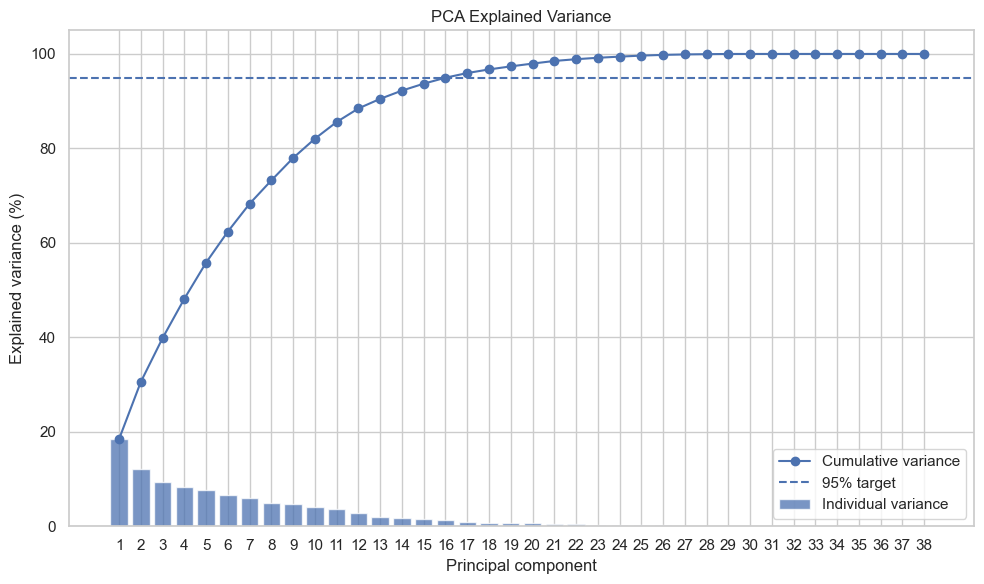

In [13]:

components = np.arange(1, len(explained_variance) + 1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    components,
    explained_variance * 100,
    alpha=0.75,
    label="Individual variance"
)

ax.plot(
    components,
    cumulative_variance * 100,
    marker="o",
    label="Cumulative variance"
)

ax.axhline(
    PCA_VARIANCE_TARGET * 100,
    linestyle="--",
    label=f"{PCA_VARIANCE_TARGET:.0%} target"
)

ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_title("PCA Explained Variance")
ax.set_xticks(components)
ax.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "pca_explained_variance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


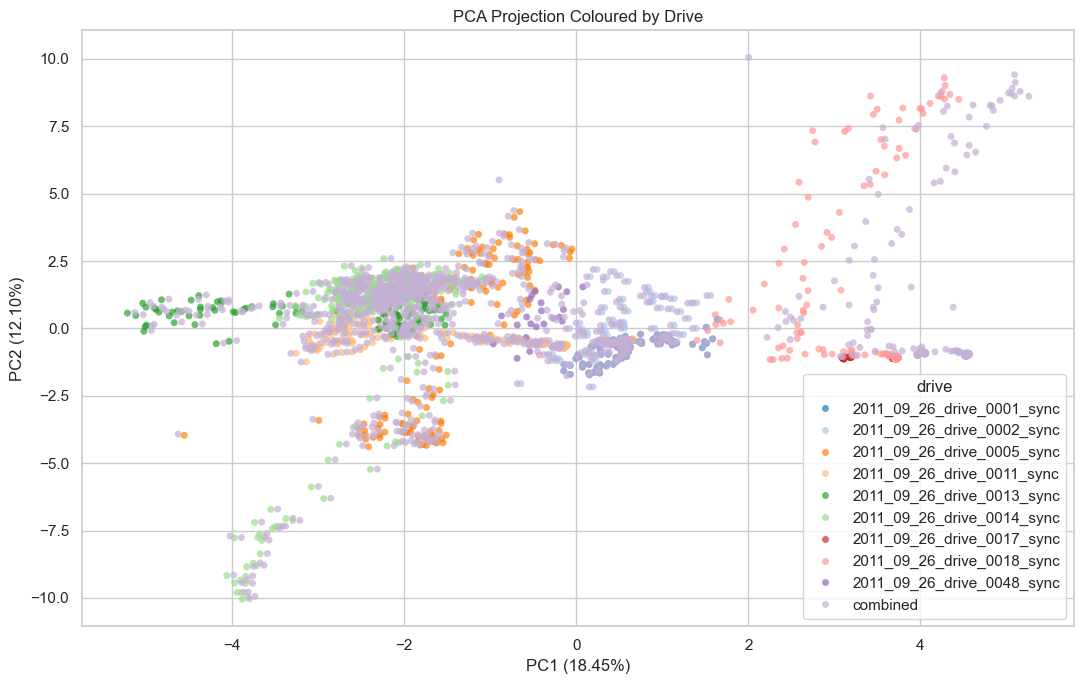

In [15]:

if X_pca.shape[1] < 2:
    raise ValueError(
        "At least two usable PCA components are required for this plot."
    )

pca_plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1]
})

if DRIVE_COL in analysis_df.columns:
    pca_plot_df["drive"] = (
        analysis_df[DRIVE_COL]
        .fillna("Unknown")
        .astype(str)
        .to_numpy()
    )

    fig, ax = plt.subplots(figsize=(11, 7))

    sns.scatterplot(
        data=pca_plot_df,
        x="PC1",
        y="PC2",
        hue="drive",
        palette="tab20",
        s=25,
        alpha=0.7,
        linewidth=0,
        ax=ax
    )

    if pca_plot_df["drive"].nunique() > 15:
        ax.legend(
            title="Drive",
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )
else:
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(
        pca_plot_df["PC1"],
        pca_plot_df["PC2"],
        s=25,
        alpha=0.7
    )

ax.set_xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}%)"
)
ax.set_title("PCA Projection Coloured by Drive")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "pca_pc1_pc2_by_drive.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [16]:

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=[f"PC{i + 1}" for i in range(n_components)]
)

display(loadings.round(4))

for pc in ["PC1", "PC2"]:
    if pc in loadings.columns:
        print(f"\nLargest absolute loadings for {pc}:")
        display(
            loadings[pc]
            .abs()
            .sort_values(ascending=False)
            .head(10)
            .to_frame("absolute_loading")
        )


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17
lat,0.2870,0.0186,0.0852,0.0522,0.1316,0.1930,0.0697,0.0837,-0.0502,0.1392,-0.1521,-0.0348,0.1928,0.2843,-0.1269,0.0041,-0.0655
lon,0.1320,-0.0109,0.0434,0.1566,0.3310,-0.2120,0.0125,-0.0094,-0.0082,-0.1879,0.3282,-0.0952,-0.1715,-0.0134,0.0423,-0.0658,0.2719
alt,-0.1370,-0.0089,-0.1132,-0.3539,0.2536,-0.0058,0.0797,0.0852,0.0176,-0.0388,0.0265,0.1528,0.0800,-0.3601,-0.1321,-0.0415,-0.1178
roll,-0.2017,0.1833,-0.0739,-0.1021,-0.0155,-0.0949,-0.0045,0.0947,-0.1387,0.3284,0.1127,0.2467,0.1447,-0.2845,0.1883,0.1522,0.0687
pitch,0.1870,0.0816,-0.2531,0.0071,-0.0332,-0.1993,0.0098,0.0297,-0.0868,0.1837,0.2609,-0.2059,0.0438,0.2256,-0.3671,-0.2538,-0.0344
yaw,0.0095,0.0267,0.1036,0.3975,0.2270,-0.1344,-0.1760,0.0474,-0.0666,-0.0260,-0.0941,0.0344,0.3026,-0.0165,-0.0523,-0.0964,0.1664
vn,-0.1843,0.1327,0.0671,0.2077,0.3772,-0.0260,-0.0205,0.0736,-0.0564,-0.0259,-0.0322,-0.1382,0.1823,0.1445,0.0299,-0.0930,0.0710
ve,-0.0781,0.0765,0.0862,0.2168,0.0391,0.1409,0.0913,0.1414,-0.2767,0.4341,0.1464,0.2355,-0.1323,0.2926,0.1167,0.0330,-0.1304
vf,-0.2699,0.1550,-0.0436,-0.1824,0.2035,0.1111,0.1383,0.0382,-0.0032,0.0218,-0.0046,-0.2148,-0.0176,0.1105,0.0356,-0.0714,0.0570
vl,-0.0142,0.2765,0.0686,0.2206,-0.1498,-0.0864,-0.0221,-0.0939,0.1937,-0.1136,-0.1622,-0.1639,0.0670,0.2316,0.3633,0.0557,-0.1079



Largest absolute loadings for PC1:


,absolute_loading
posmode,0.288004
lat,0.287043
pos_accuracy,0.285254
velmode,0.278600
vel_accuracy,0.272223
speed,0.269879
speed_2d,0.269878
vf,0.269865
orimode,0.267785
numsats,0.210073



Largest absolute loadings for PC2:


,absolute_loading
ay,0.438973
wz,0.422419
wu,0.422377
al,0.421172
vl,0.276492
roll,0.183296
speed,0.155072
speed_2d,0.155063
vf,0.155039
vn,0.132688


In [17]:

cluster_results = []
cluster_models = {}

for k in CLUSTER_COUNTS:
    if k >= len(X_pca):
        warnings.warn(f"Skipping K={k}: insufficient observations.")
        continue

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    if len(np.unique(labels)) < 2:
        score = np.nan
    else:
        sample_size = min(10000, len(X_pca))

        score = silhouette_score(
            X_pca,
            labels,
            sample_size=(
                sample_size if sample_size < len(X_pca) else None
            ),
            random_state=RANDOM_STATE
        )

    cluster_models[k] = (model, labels)

    cluster_results.append({
        "k": k,
        "silhouette_score": score,
        "inertia": model.inertia_
    })

cluster_metrics = pd.DataFrame(cluster_results)

if cluster_metrics.empty or cluster_metrics["silhouette_score"].notna().sum() == 0:
    raise ValueError("Unable to evaluate a valid K-means clustering.")

display(cluster_metrics.round(4))


,k,silhouette_score,inertia
0,3,0.2599,78453.9415
1,4,0.2878,70776.8790
2,5,0.2779,64701.6828


Selected K: 4
Silhouette score: 0.2878


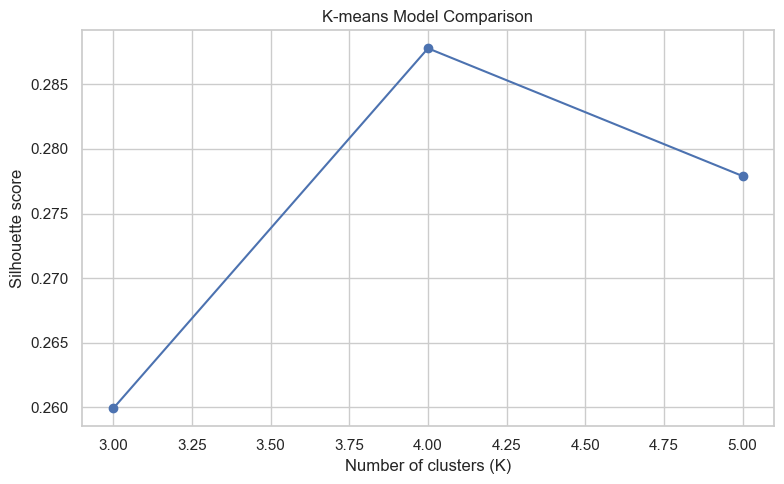

In [18]:

valid_metrics = cluster_metrics.dropna(
    subset=["silhouette_score"]
)

best_k = int(
    valid_metrics.loc[
        valid_metrics["silhouette_score"].idxmax(), "k"
    ]
)

best_model, best_labels = cluster_models[best_k]

analysis_df["cluster"] = best_labels

print("Selected K:", best_k)
print(
    "Silhouette score:",
    round(
        float(valid_metrics["silhouette_score"].max()),
        4
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    cluster_metrics["k"],
    cluster_metrics["silhouette_score"],
    marker="o"
)

ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette score")
ax.set_title("K-means Model Comparison")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "kmeans_silhouette_scores.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

cluster_metrics.to_csv(
    OUTPUT_DIR / "cluster_metrics.csv",
    index=False
)


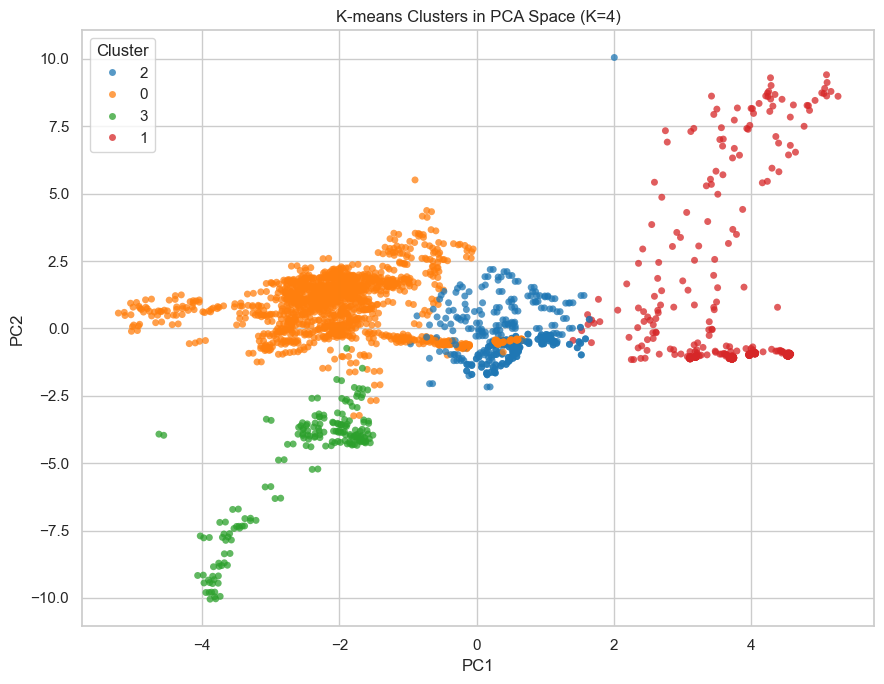

,row_count
cluster,
0,1505
1,766
2,414
3,187


In [19]:

pca_cluster_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": best_labels.astype(str)
})

fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_cluster_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=25,
    alpha=0.75,
    linewidth=0,
    ax=ax
)

ax.set_title(f"K-means Clusters in PCA Space (K={best_k})")
ax.legend(title="Cluster")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "pca_clusters.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

display(
    analysis_df["cluster"]
    .value_counts()
    .sort_index()
    .rename("row_count")
    .to_frame()
)


In [20]:

if X_COL not in analysis_df.columns or Y_COL not in analysis_df.columns:
    print(
        f"Trajectory plot skipped. Configure X_COL='{X_COL}' "
        f"and Y_COL='{Y_COL}' to match your coordinate columns."
    )
else:
    trajectory_df = analysis_df.copy()

    trajectory_df[X_COL] = pd.to_numeric(
        trajectory_df[X_COL], errors="coerce"
    )
    trajectory_df[Y_COL] = pd.to_numeric(
        trajectory_df[Y_COL], errors="coerce"
    )

    trajectory_df = trajectory_df.dropna(
        subset=[X_COL, Y_COL]
    )

    sort_cols = []
    if DRIVE_COL in trajectory_df.columns:
        sort_cols.append(DRIVE_COL)
    if ORDER_COL in trajectory_df.columns:
        sort_cols.append(ORDER_COL)

    if sort_cols:
        trajectory_df = trajectory_df.sort_values(sort_cols)

    fig, ax = plt.subplots(figsize=(10, 8))

    # Draw trajectory paths in chronological order.
    if DRIVE_COL in trajectory_df.columns:
        for _, group in trajectory_df.groupby(
            DRIVE_COL, dropna=False, sort=False
        ):
            ax.plot(
                group[X_COL],
                group[Y_COL],
                color="gray",
                alpha=0.35,
                linewidth=0.8
            )
    else:
        ax.plot(
            trajectory_df[X_COL],
            trajectory_df[Y_COL],
            color="gray",
            alpha=0.35,
            linewidth=0.8
        )

    # Overlay cluster labels.
    sns.scatterplot(
        data=trajectory_df,
        x=X_COL,
        y=Y_COL,
        hue="cluster",
        palette="tab10",
        s=25,
        alpha=0.8,
        linewidth=0,
        ax=ax
    )

    ax.set_xlabel(X_COL)
    ax.set_ylabel(Y_COL)
    ax.set_title(f"Trajectory Coloured by Cluster (K={best_k})")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(title="Cluster")
    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / "trajectory_clusters.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


Trajectory plot skipped. Configure X_COL='x' and Y_COL='y' to match your coordinate columns.
